# Stock Market Analysis & LSTM Price Prediction

**Goal:** analyse recent price behaviour of four large tech stocks (AAPL, GOOG, MSFT, AMZN) and train an LSTM network to predict the next-day closing price of one stock.

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, yfinance, scikit-learn, TensorFlow/Keras.

**Questions answered**
1. How did the price and trading volume change over time?
2. What do the 10/20/50-day moving averages show?
3. What were the daily returns?
4. How correlated are the stocks with each other?
5. How much risk (volatility) does each stock carry versus its expected return?
6. Can an LSTM predict the next closing price, and does it beat a naive baseline?

**Data:** Yahoo Finance via `yfinance`.

## Getting the data
Data is downloaded directly from Yahoo Finance with `yfinance` (last 12 months for the analysis sections, daily data from 2012 for the LSTM).

# 1. How did the price change over time?
Price and trading volume history of each stock over the last 12 months.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
plt.style.use("fivethirtyeight")
%matplotlib inline

# For reading stock data from yahoo
import yfinance as yf


# For time stamps
from datetime import datetime


# The tech stocks we'll use for this analysis
tech_list = ['AAPL', 'GOOG', 'MSFT', 'AMZN']

# Set up End and Start times for data grab
tech_list = ['AAPL', 'GOOG', 'MSFT', 'AMZN']

end = datetime.now()
start = datetime(end.year - 1, end.month, end.day)

for stock in tech_list:
    globals()[stock] = yf.download(stock, start=start, end=end,
                                   auto_adjust=False, multi_level_index=False)
    

company_list = [AAPL, GOOG, MSFT, AMZN]
company_name = ["APPLE", "GOOGLE", "MICROSOFT", "AMAZON"]

for company, com_name in zip(company_list, company_name):
    company["company_name"] = com_name
    
df = pd.concat(company_list, axis=0)
df.tail(10)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


,Adj Close,Close,High,Low,Open,Volume,company_name
Date,,,,,,,
2026-09-22,254.979996,254.979996,259.000000,253.779999,255.110001,41982600,AMAZON
2026-09-23,249.270004,249.270004,253.990005,247.759995,253.000000,44209200,AMAZON
2026-09-24,249.380005,249.380005,250.429993,245.600006,246.020004,33040100,AMAZON
2026-09-25,249.669998,249.669998,250.880005,247.179993,248.559998,34263900,AMAZON
2026-09-28,246.149994,246.149994,247.770004,244.729996,246.630005,32596700,AMAZON
2026-09-29,246.669998,246.669998,248.839996,245.139999,246.710007,33730400,AMAZON
2026-09-30,249.149994,249.149994,252.440002,246.080002,246.789993,41913100,AMAZON
2026-10-01,248.229996,248.229996,251.830002,246.119995,251.610001,33243900,AMAZON
2026-10-02,251.520004,251.520004,253.559998,250.020004,251.509995,33433400,AMAZON


The data is numeric and indexed by date. Weekends and market holidays are missing from the records.

## Descriptive statistics

In [2]:
# Summary statistics
AAPL.describe()

,Adj Close,Close,High,Low,Open,Volume
count,251.000000,251.000000,251.000000,251.000000,251.000000,2.510000e+02
mean,284.696574,285.153227,288.054304,282.071155,284.879960,4.813636e+07
std,27.212124,26.987800,27.156197,26.521673,26.643339,2.147242e+07
min,244.367310,245.270004,248.850006,243.419998,246.600006,1.791060e+07
25%,261.827805,262.644989,265.425003,259.679993,262.210007,3.739245e+07
50%,274.912903,275.250000,278.950012,272.859985,275.269989,4.398910e+07
75%,308.878616,309.130005,311.809998,305.789993,308.534988,5.141735e+07
max,341.070007,341.070007,345.339996,338.750000,341.079987,2.617755e+08


Each stock has 251 trading days in the last 12 months (weekends and holidays are excluded).

## Data info
Column types and non-null counts.

In [3]:
# General info
AAPL.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 251 entries, 2025-10-06 to 2026-10-05
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Adj Close     251 non-null    float64
 1   Close         251 non-null    float64
 2   High          251 non-null    float64
 3   Low           251 non-null    float64
 4   Open          251 non-null    float64
 5   Volume        251 non-null    int64  
 6   company_name  251 non-null    str    
dtypes: float64(5), int64(1), str(1)
memory usage: 15.7 KB


## Closing price
The closing price is the last traded price of the day and the standard benchmark for tracking performance.

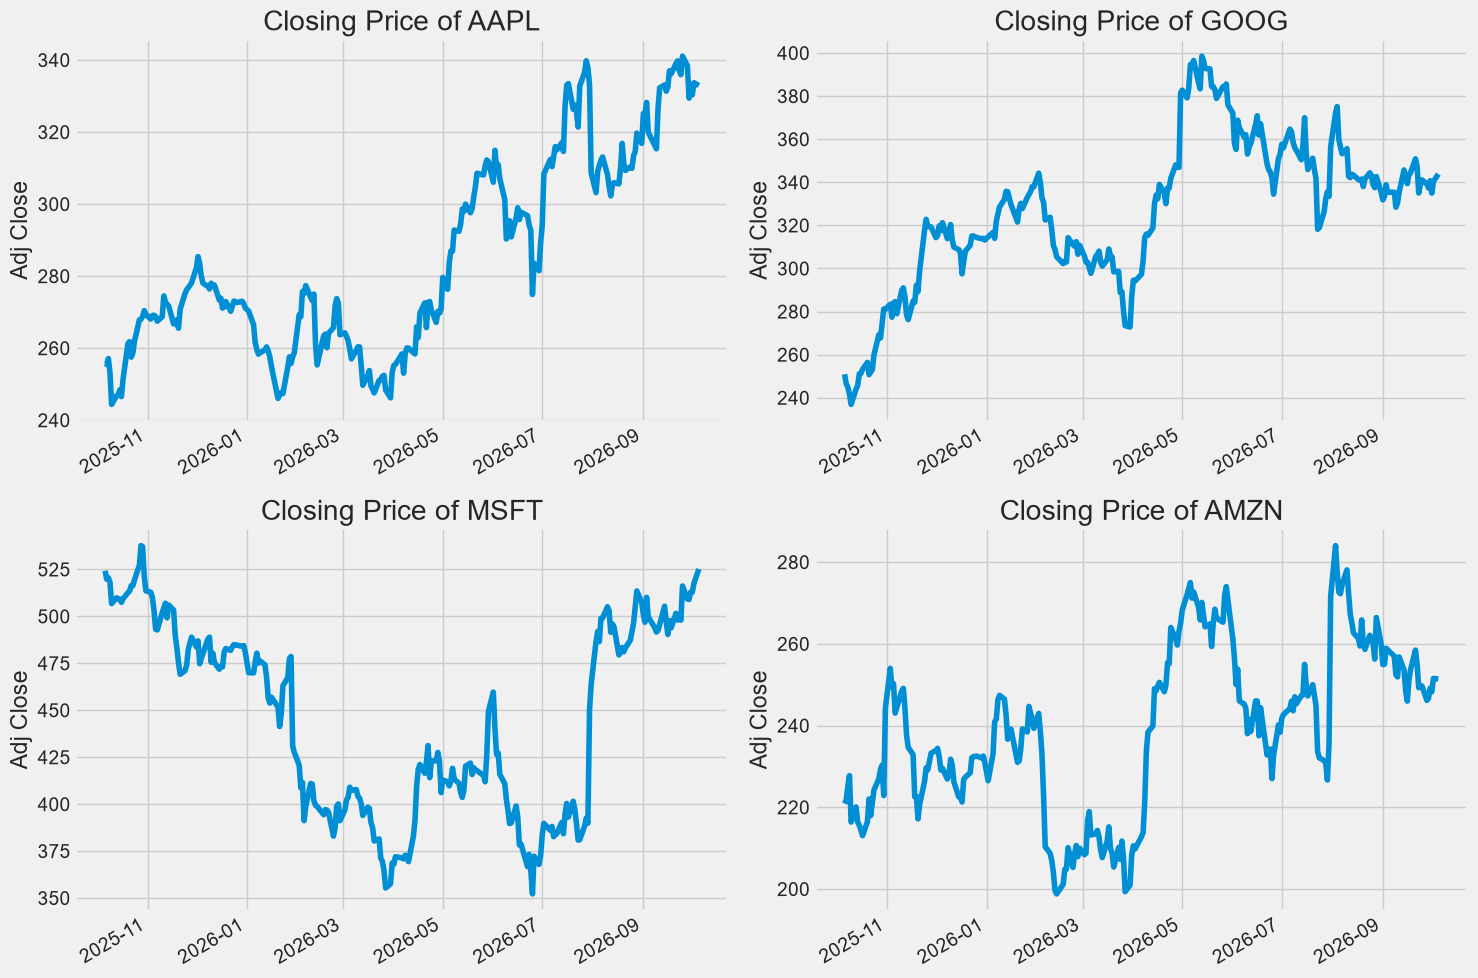

In [4]:
# Closing price history
plt.figure(figsize=(15, 10))
plt.subplots_adjust(top=1.25, bottom=1.2)

for i, company in enumerate(company_list, 1):
    plt.subplot(2, 2, i)
    company['Adj Close'].plot()
    plt.ylabel('Adj Close')
    plt.xlabel(None)
    plt.title(f"Closing Price of {tech_list[i - 1]}")
    
plt.tight_layout()

## Trading volume
Volume is the number of shares traded each day.

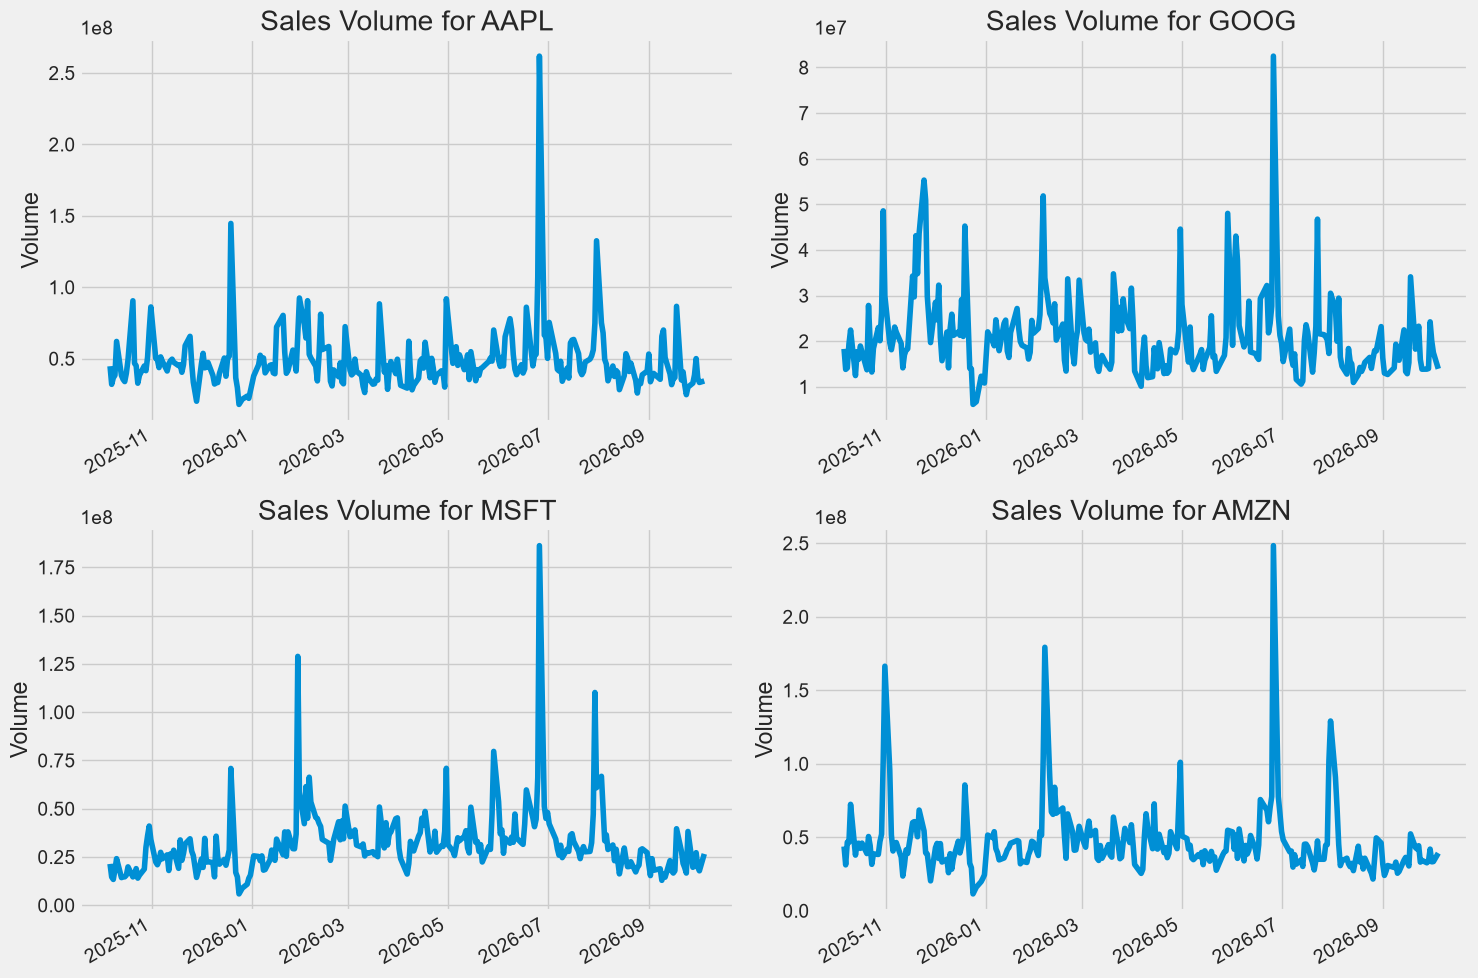

In [5]:
# Daily trading volume
plt.figure(figsize=(15, 10))
plt.subplots_adjust(top=1.25, bottom=1.2)

for i, company in enumerate(company_list, 1):
    plt.subplot(2, 2, i)
    company['Volume'].plot()
    plt.ylabel('Volume')
    plt.xlabel(None)
    plt.title(f"Sales Volume for {tech_list[i - 1]}")
    
plt.tight_layout()

Next, moving averages are used to smooth out the daily noise.

# 2. Moving averages
A moving average (MA) smooths the price by averaging it over a fixed window: 10, 20 and 50 days here.

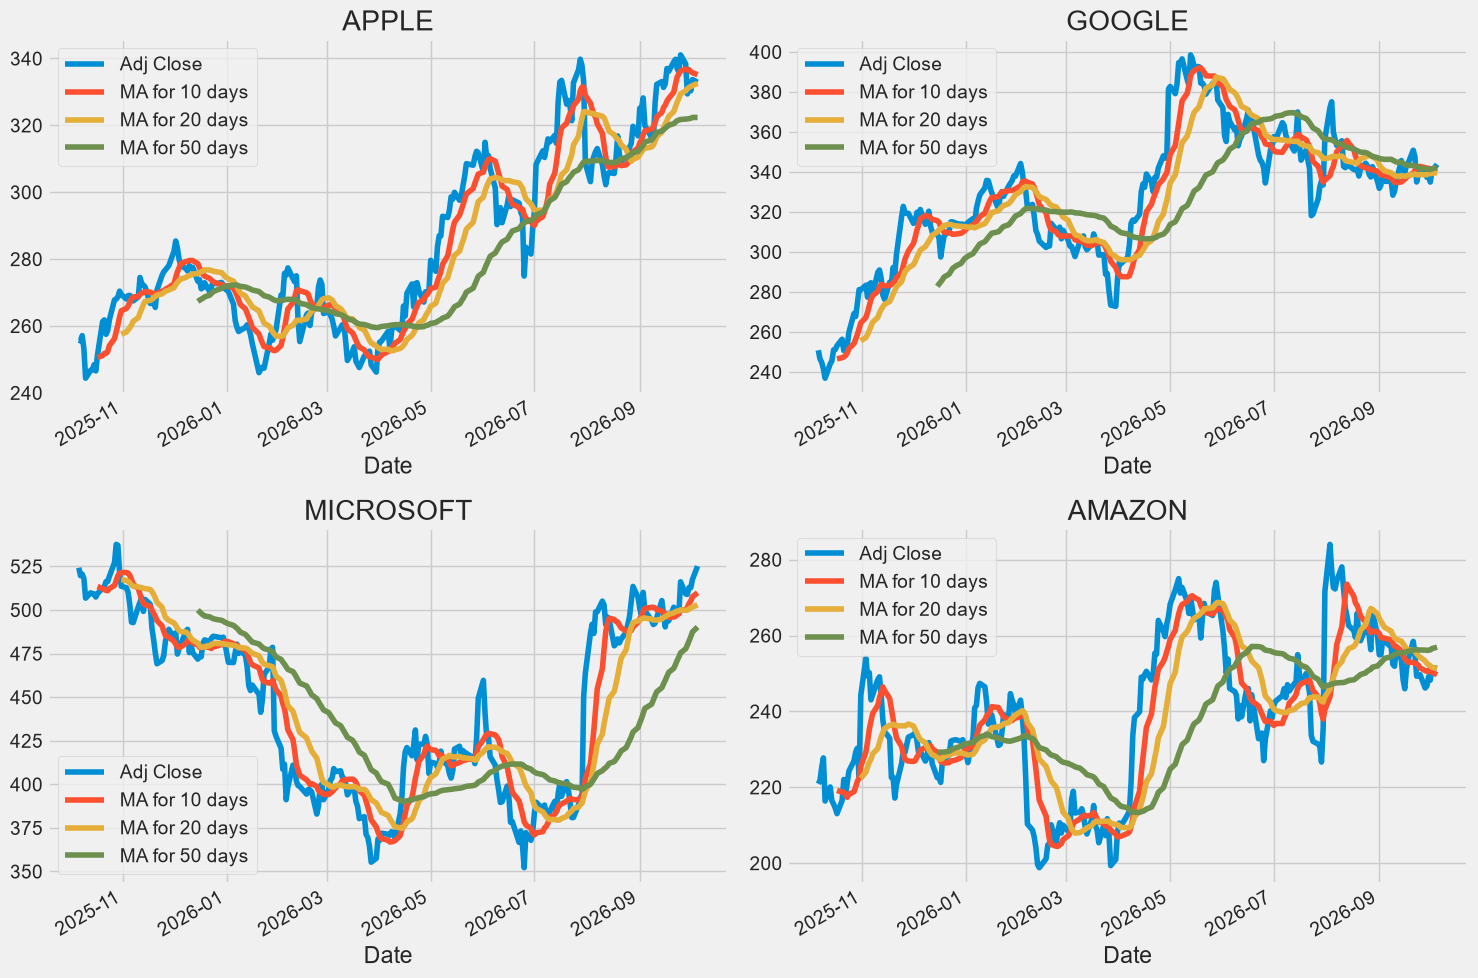

In [6]:
ma_day = [10, 20, 50]

for ma in ma_day:
    for company in company_list:
        column_name = f"MA for {ma} days"
        company[column_name] = company['Adj Close'].rolling(ma).mean()
        

fig, axes = plt.subplots(nrows=2, ncols=2)
fig.set_figheight(10)
fig.set_figwidth(15)

AAPL[['Adj Close', 'MA for 10 days', 'MA for 20 days', 'MA for 50 days']].plot(ax=axes[0,0])
axes[0,0].set_title('APPLE')

GOOG[['Adj Close', 'MA for 10 days', 'MA for 20 days', 'MA for 50 days']].plot(ax=axes[0,1])
axes[0,1].set_title('GOOGLE')

MSFT[['Adj Close', 'MA for 10 days', 'MA for 20 days', 'MA for 50 days']].plot(ax=axes[1,0])
axes[1,0].set_title('MICROSOFT')

AMZN[['Adj Close', 'MA for 10 days', 'MA for 20 days', 'MA for 50 days']].plot(ax=axes[1,1])
axes[1,1].set_title('AMAZON')

fig.tight_layout()

The 10- and 20-day averages follow the price closely while removing day-to-day noise. The 50-day average is smoother and lags further behind.

# 3. Daily returns

The daily return is the percentage change of the price from the previous day. It describes risk more directly than the price level.

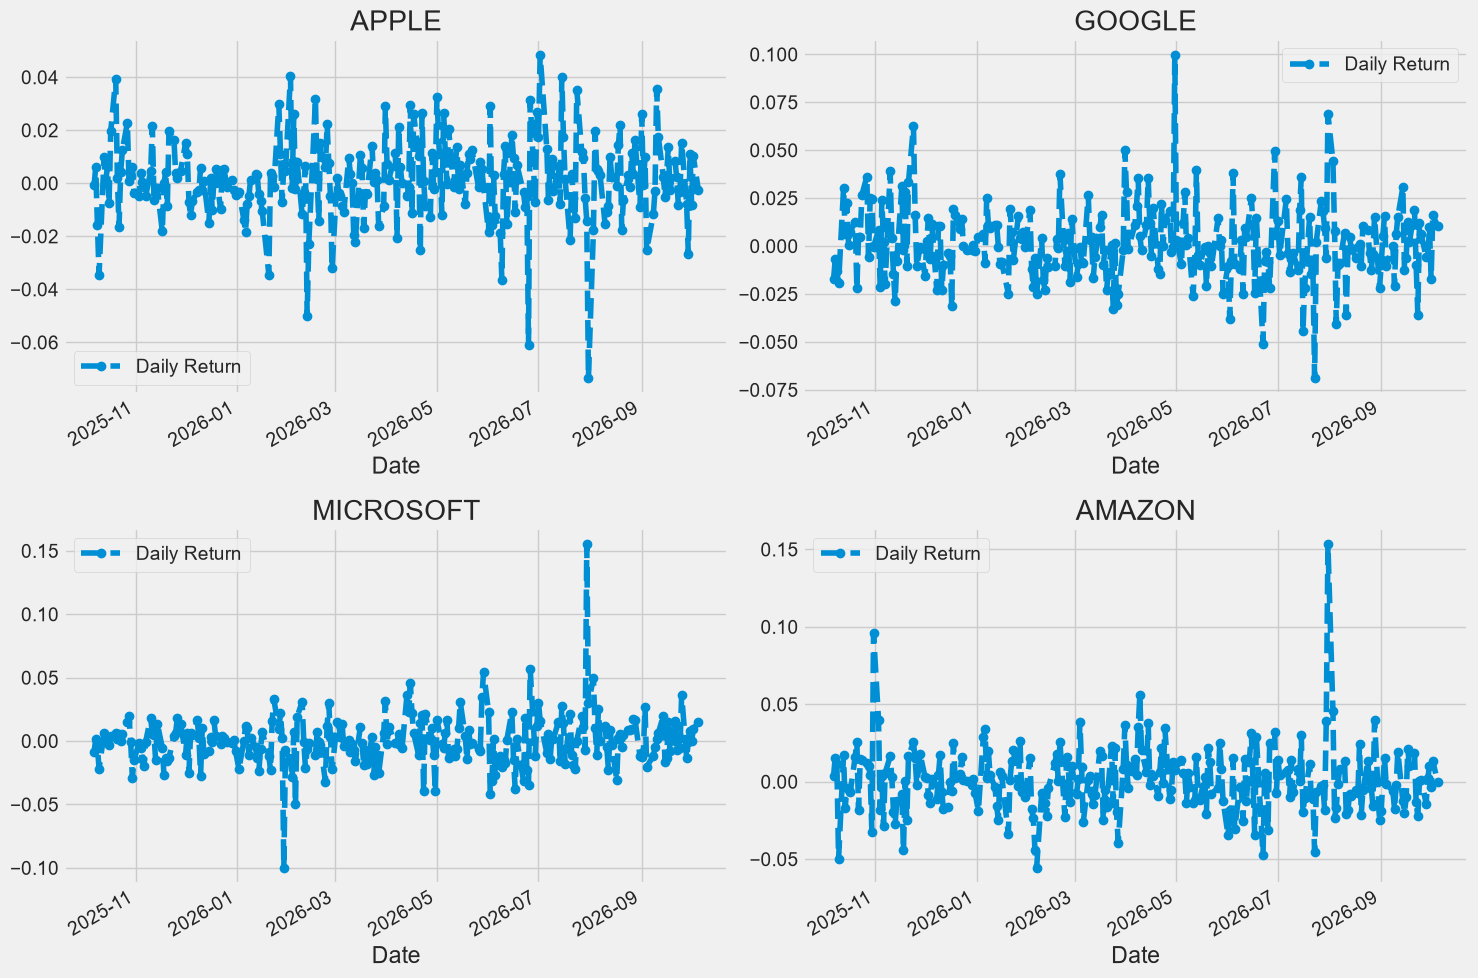

In [7]:
# Daily return = percentage change of the adjusted close
for company in company_list:
    company['Daily Return'] = company['Adj Close'].pct_change()

# Then we'll plot the daily return percentage
fig, axes = plt.subplots(nrows=2, ncols=2)
fig.set_figheight(10)
fig.set_figwidth(15)

AAPL['Daily Return'].plot(ax=axes[0,0], legend=True, linestyle='--', marker='o')
axes[0,0].set_title('APPLE')

GOOG['Daily Return'].plot(ax=axes[0,1], legend=True, linestyle='--', marker='o')
axes[0,1].set_title('GOOGLE')

MSFT['Daily Return'].plot(ax=axes[1,0], legend=True, linestyle='--', marker='o')
axes[1,0].set_title('MICROSOFT')

AMZN['Daily Return'].plot(ax=axes[1,1], legend=True, linestyle='--', marker='o')
axes[1,1].set_title('AMAZON')

fig.tight_layout()

Histograms show how the daily returns are distributed around zero.

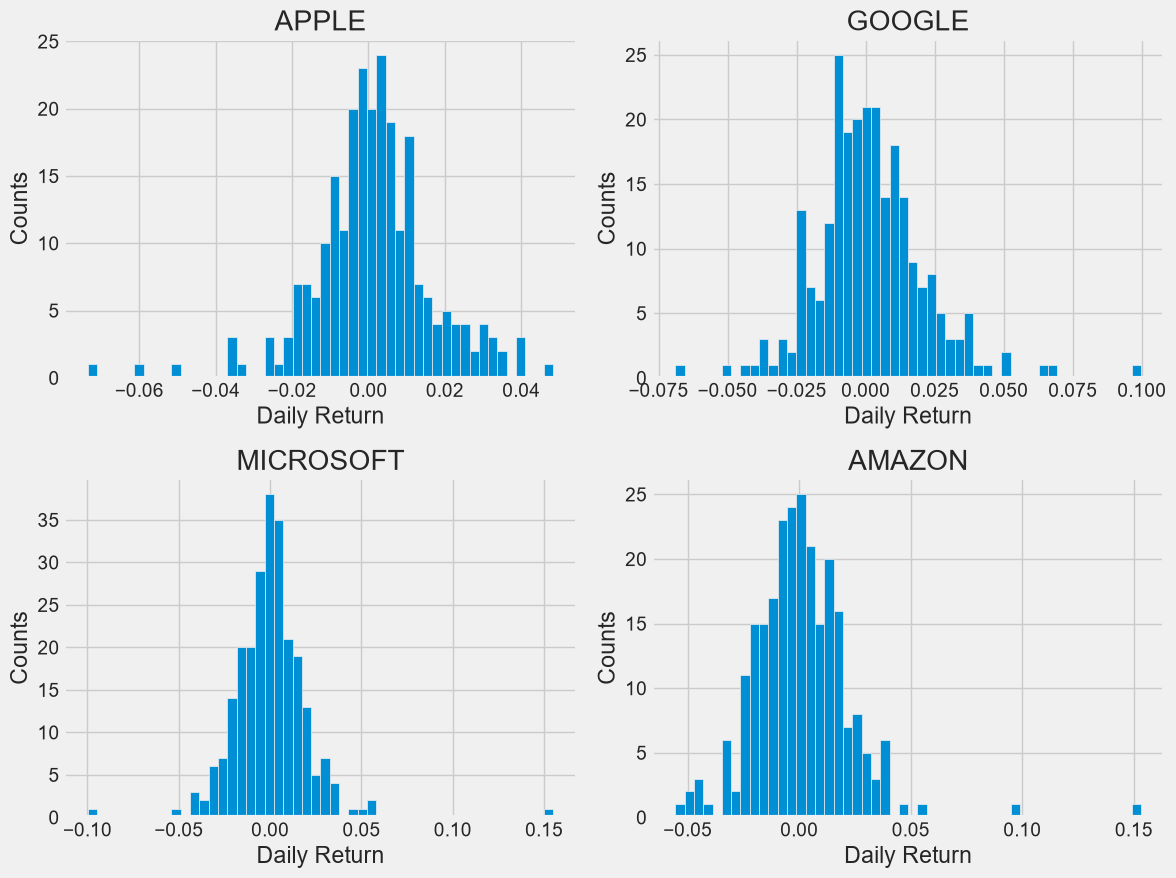

In [8]:
plt.figure(figsize=(12, 9))

for i, company in enumerate(company_list, 1):
    plt.subplot(2, 2, i)
    company['Daily Return'].hist(bins=50)
    plt.xlabel('Daily Return')
    plt.ylabel('Counts')
    plt.title(f'{company_name[i - 1]}')
    
plt.tight_layout()

# 4. Correlation between the stocks

Correlation measures how closely two series move together (from -1 to +1). It does not show causation. The adjusted closing prices of all four stocks are put into one DataFrame to compare them.

In [9]:
# Adjusted closing prices of all four stocks in one DataFrame

closing_df = yf.download(tech_list, start=start, end=end, auto_adjust=False)['Adj Close']

# Make a new tech returns DataFrame
tech_rets = closing_df.pct_change()
tech_rets.head()

[*********************100%***********************]  4 of 4 completed


Ticker,AAPL,AMZN,GOOG,MSFT
Date,,,,
2025-10-06,NaN,NaN,NaN,NaN
2025-10-07,-0.000818,0.003984,-0.017415,-0.008684
2025-10-08,0.006160,0.015511,-0.006758,0.001661
2025-10-09,-0.015578,0.011189,-0.013240,-0.004668
2025-10-10,-0.034522,-0.049925,-0.019487,-0.021899


A stock compared with itself gives a perfect straight line (correlation = 1).

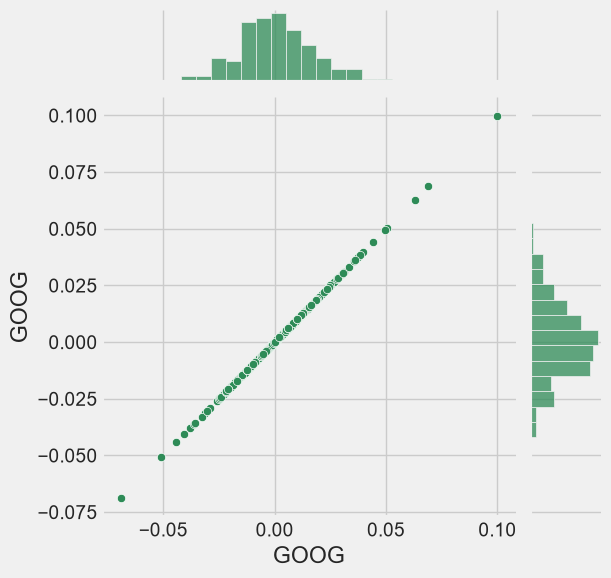

In [10]:
# GOOG vs itself: perfect linear relationship (sanity check)
sns.jointplot(x='GOOG', y='GOOG', data=tech_rets, kind='scatter', color='seagreen')

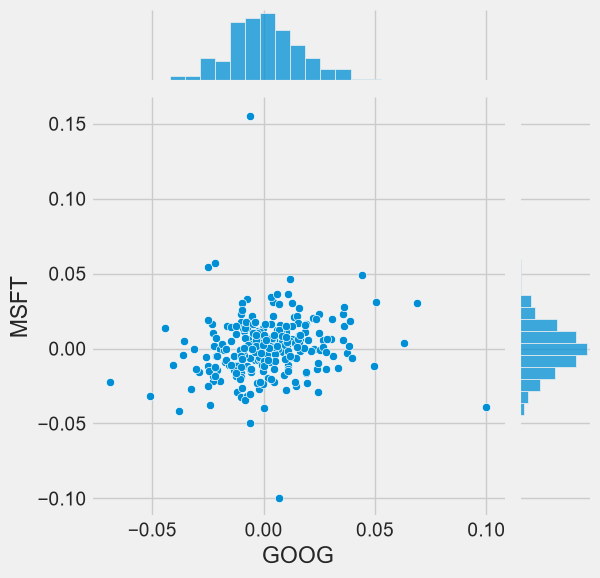

In [11]:
# Daily returns: GOOG vs MSFT
sns.jointplot(x='GOOG', y='MSFT', data=tech_rets, kind='scatter')

If the daily returns of two stocks are strongly positively correlated, their scatter plot shows an upward linear pattern. `sns.pairplot()` repeats this comparison for every pair of stocks.

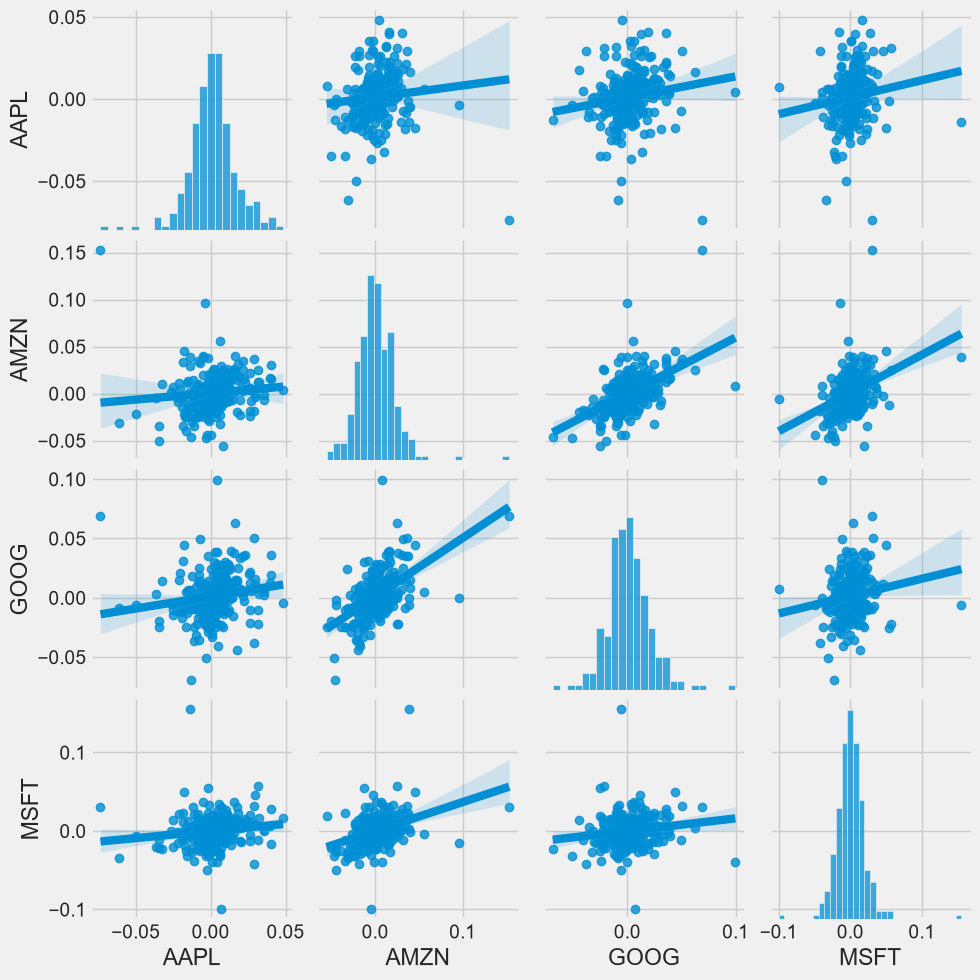

In [12]:
# Pairwise scatter plots of daily returns

sns.pairplot(tech_rets, kind='reg')

In the pair plots, GOOG and AMZN show the clearest linear relationship in daily returns. `sns.PairGrid()` gives more control over the layout: scatter plots above the diagonal, KDE plots below and histograms on the diagonal.

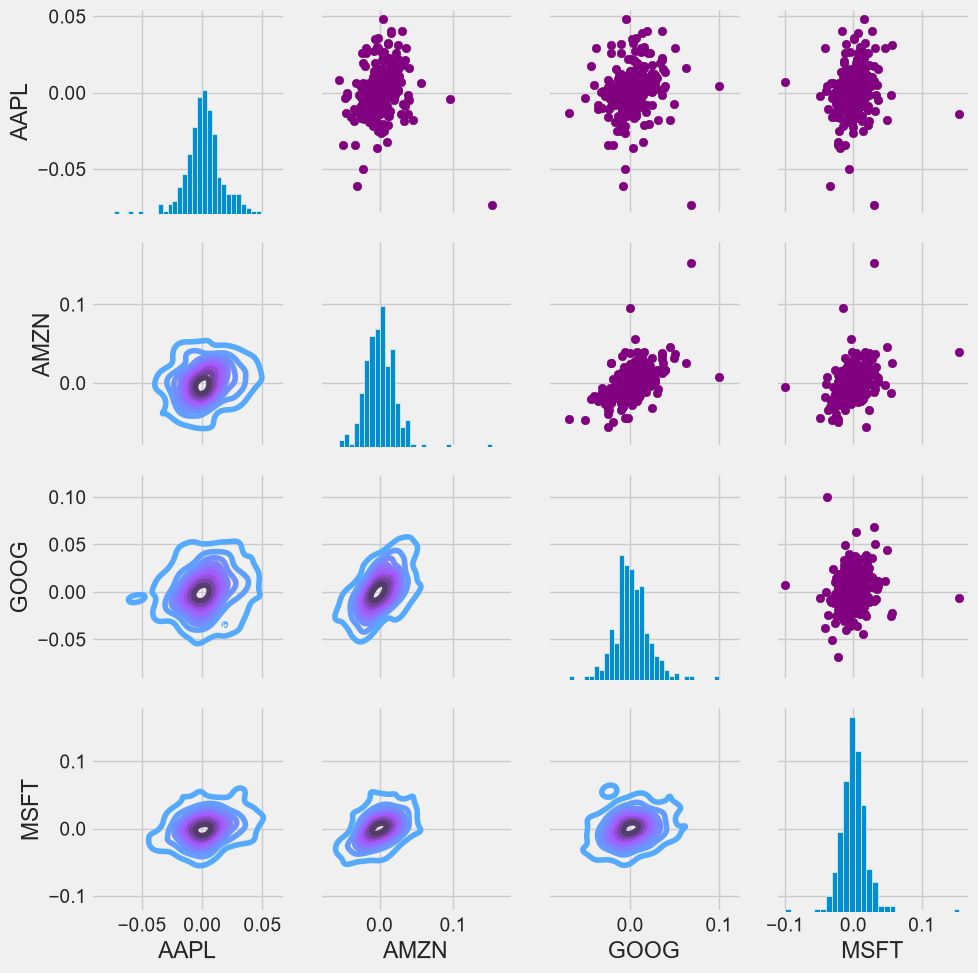

In [13]:
# Pair grid of daily returns: scatter (upper), KDE (lower), histogram (diagonal)
return_fig = sns.PairGrid(tech_rets.dropna())

# Using map_upper we can specify what the upper triangle will look like.
return_fig.map_upper(plt.scatter, color='purple')

# We can also define the lower triangle in the figure, inclufing the plot type (kde) 
# or the color map (BluePurple)
return_fig.map_lower(sns.kdeplot, cmap='cool_d')

# Finally we'll define the diagonal as a series of histogram plots of the daily return
return_fig.map_diag(plt.hist, bins=30)

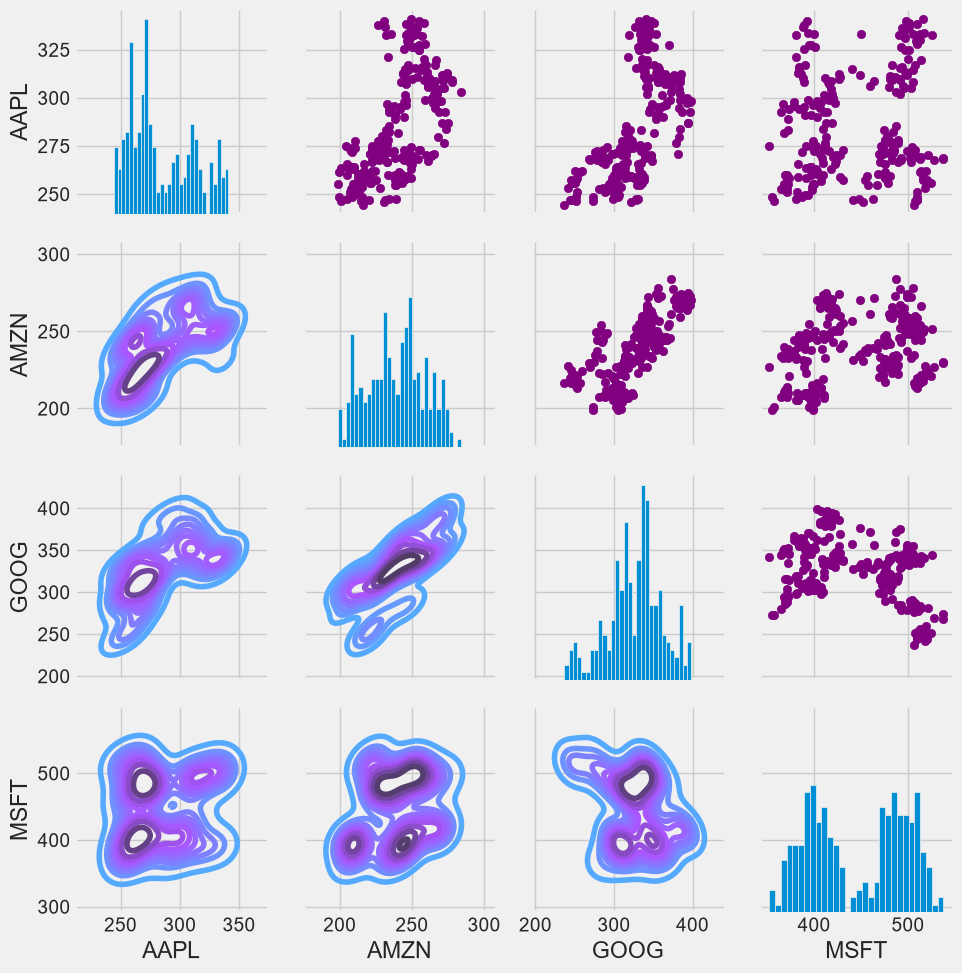

In [14]:
# Pair grid of closing prices, same layout
returns_fig = sns.PairGrid(closing_df)

# Using map_upper we can specify what the upper triangle will look like.
returns_fig.map_upper(plt.scatter,color='purple')

# We can also define the lower triangle in the figure, inclufing the plot type (kde) or the color map (BluePurple)
returns_fig.map_lower(sns.kdeplot,cmap='cool_d')

# Finally we'll define the diagonal as a series of histogram plots of the daily return
returns_fig.map_diag(plt.hist,bins=30)

Correlation heatmaps give the exact values for daily returns (left) and closing prices (right).

Text(0.5, 1.0, 'Correlation of stock closing price')

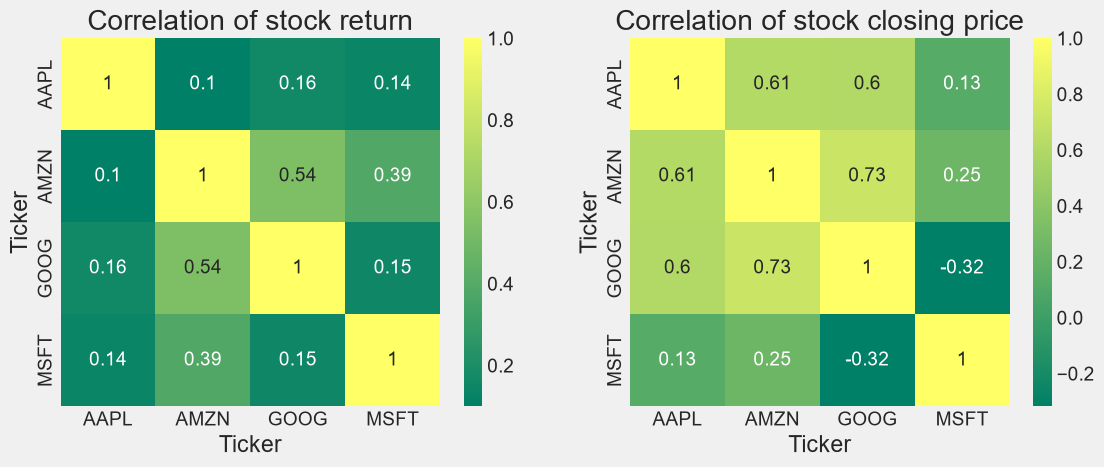

In [15]:
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
sns.heatmap(tech_rets.corr(), annot=True, cmap='summer')
plt.title('Correlation of stock return')

plt.subplot(2, 2, 2)
sns.heatmap(closing_df.corr(), annot=True, cmap='summer')
plt.title('Correlation of stock closing price')

- Daily returns of all four stocks are positively correlated. The strongest pairs are AMZN–GOOG (0.54) and AMZN–MSFT (0.39); AAPL is the least correlated with the others (0.10–0.16).
- Closing prices show a different picture: AMZN–GOOG is highest (0.73) and MSFT–GOOG is negative (-0.32). Price-level correlations are less reliable than return correlations because any two trending series can look correlated.
- Moderate return correlations mean holding these stocks together gives some diversification.

# 5. Risk vs expected return

A simple way to measure risk is to compare each stock's expected (mean) daily return with the standard deviation of its daily returns.

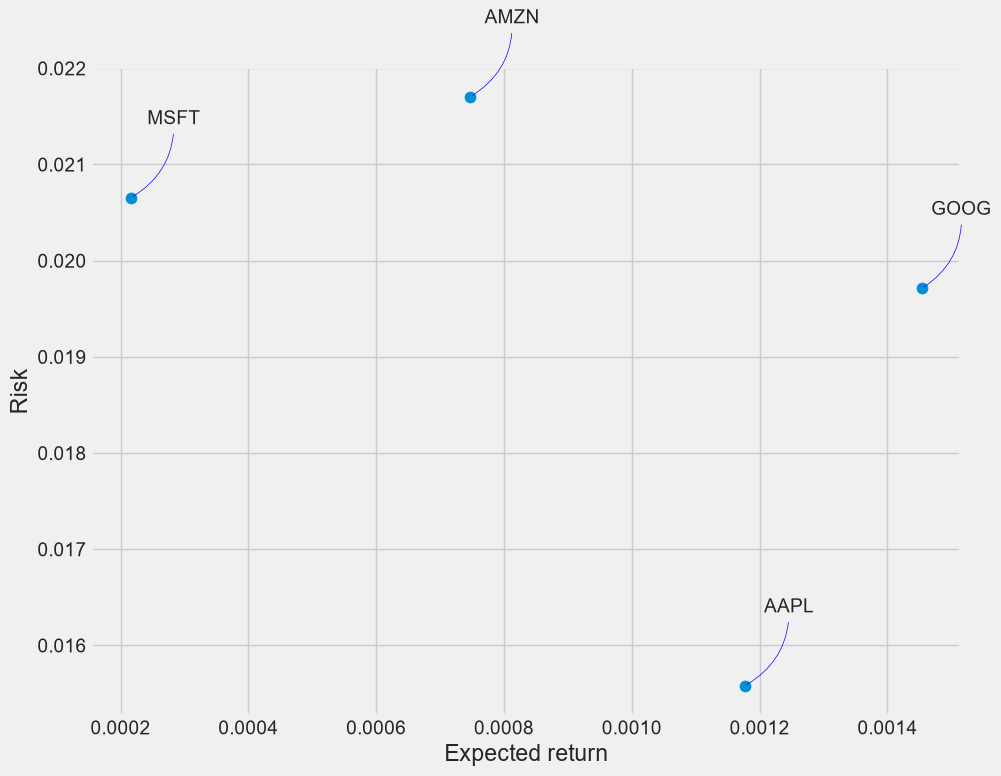

In [16]:
rets = tech_rets.dropna()

area = np.pi * 20

plt.figure(figsize=(10, 8))
plt.scatter(rets.mean(), rets.std(), s=area)
plt.xlabel('Expected return')
plt.ylabel('Risk')

for label, x, y in zip(rets.columns, rets.mean(), rets.std()):
    plt.annotate(label, xy=(x, y), xytext=(50, 50), textcoords='offset points', ha='right', va='bottom', 
                 arrowprops=dict(arrowstyle='-', color='blue', connectionstyle='arc3,rad=-0.3'))

## Extra analysis: relative performance, volatility and Bollinger Bands
The next three charts show which stock gained the most, how its risk changed over time, and how far price moves away from its recent average.

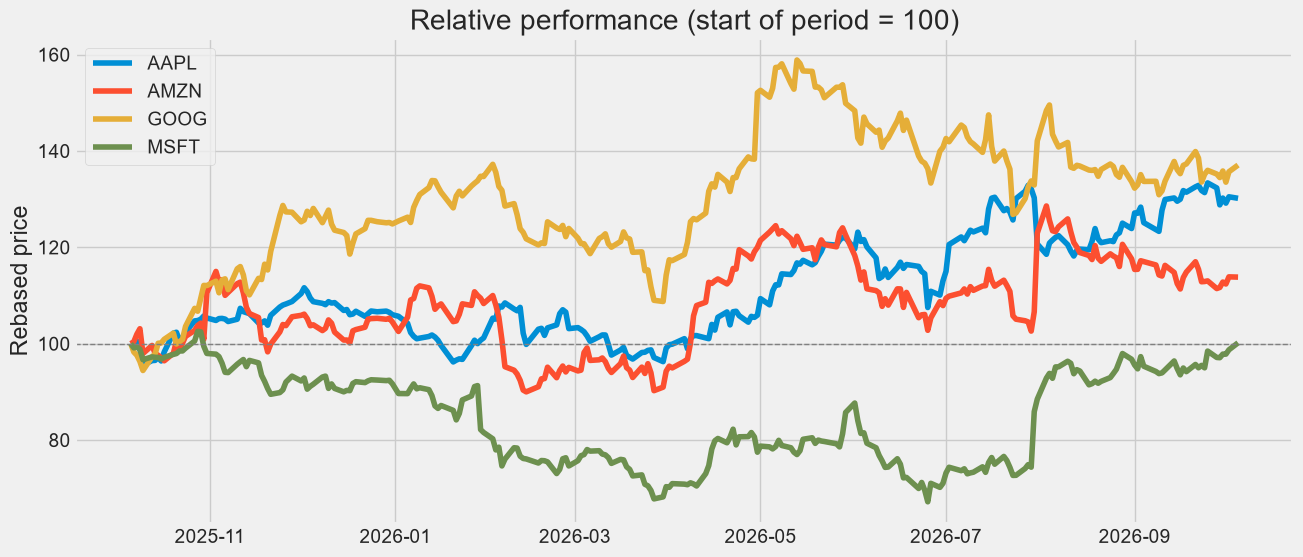

Total return over the period (%):
Ticker
GOOG    37.1
AAPL    30.2
AMZN    13.8
MSFT     0.2
Name: 2026-10-05 00:00:00, dtype: float64


In [17]:
# Rebase every stock to 100 at the start of the period
rebased = closing_df / closing_df.iloc[0] * 100

plt.figure(figsize=(14, 6))
for col in rebased.columns:
    plt.plot(rebased.index, rebased[col], label=col)
plt.axhline(100, color='gray', linestyle='--', linewidth=1)
plt.title('Relative performance (start of period = 100)')
plt.ylabel('Rebased price')
plt.legend()
plt.show()

print("Total return over the period (%):")
print((rebased.iloc[-1] - 100).round(1).sort_values(ascending=False))

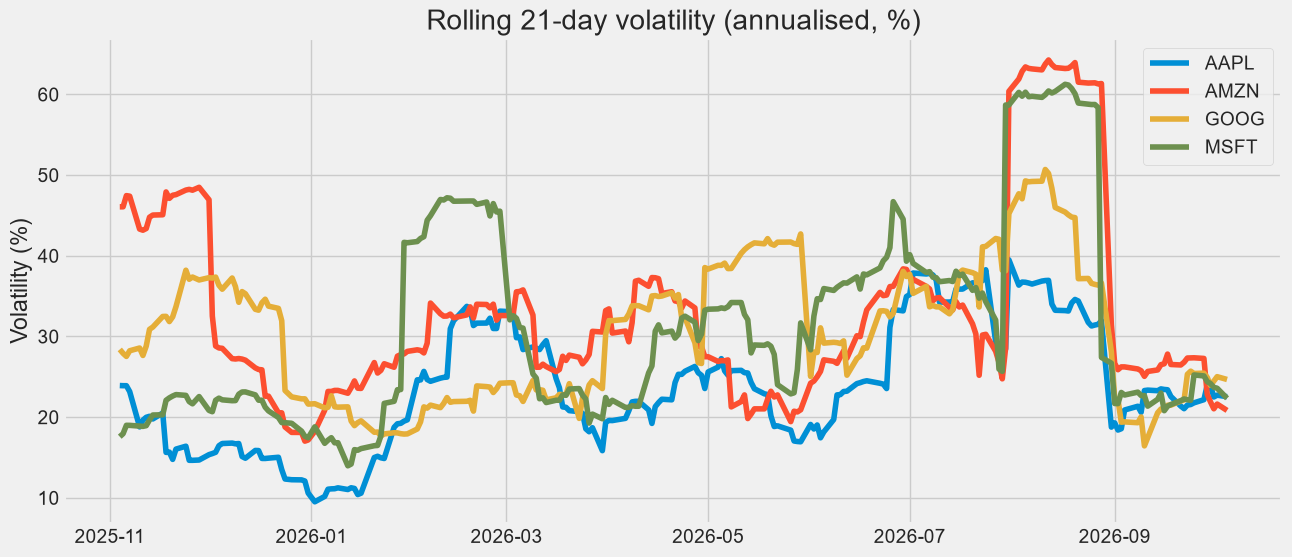

In [18]:
# 21-day rolling standard deviation of daily returns, annualised (x sqrt(252))
rolling_vol = tech_rets.rolling(21).std() * np.sqrt(252) * 100

plt.figure(figsize=(14, 6))
for col in rolling_vol.columns:
    plt.plot(rolling_vol.index, rolling_vol[col], label=col)
plt.title('Rolling 21-day volatility (annualised, %)')
plt.ylabel('Volatility (%)')
plt.legend()
plt.show()

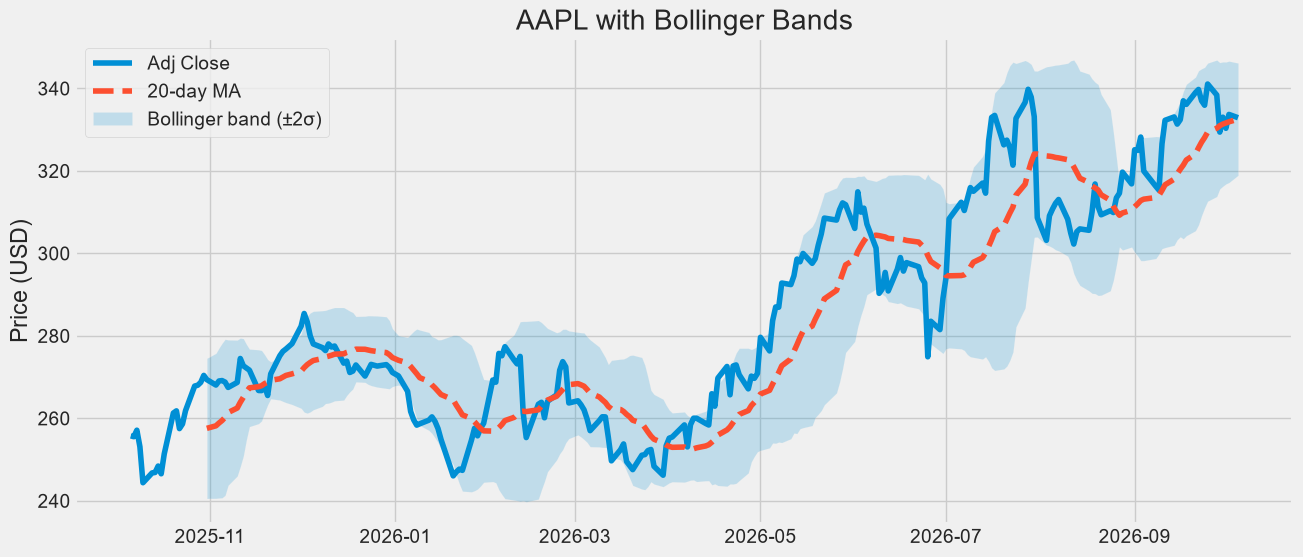

In [19]:
# Bollinger Bands for AAPL: 20-day moving average +/- 2 standard deviations
price = AAPL['Adj Close']
ma20 = price.rolling(20).mean()
std20 = price.rolling(20).std()

plt.figure(figsize=(14, 6))
plt.plot(price, label='Adj Close')
plt.plot(ma20, label='20-day MA', linestyle='--')
plt.fill_between(price.index, ma20 - 2 * std20, ma20 + 2 * std20, alpha=0.2, label='Bollinger band (±2σ)')
plt.title('AAPL with Bollinger Bands')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

# 6. Predicting the closing price with an LSTM
We use the previous 60 trading days of closing prices to predict the next day's close. The first 95% of the data (in time order) is used for training, the last 5% for testing.

In [20]:
# Choose the stock to model (change this to try another ticker)
TICKER = 'AAPL'

# Daily price history from 2012 onwards
df = yf.download(TICKER, start='2012-01-01', end=datetime.now(),
                 auto_adjust=False, multi_level_index=False)
df

[*********************100%***********************]  1 of 1 completed


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2012-01-03,12.299736,14.686786,14.732143,14.607143,14.621429,302220800
2012-01-04,12.365838,14.765714,14.810000,14.617143,14.642857,260022000
2012-01-05,12.503125,14.929643,14.948214,14.738214,14.819643,271269600
2012-01-06,12.633825,15.085714,15.098214,14.972143,14.991786,318292800
2012-01-09,12.613791,15.061786,15.276786,15.048214,15.196429,394024400
...,...,...,...,...,...,...
2026-09-29,329.399994,329.399994,337.089996,328.700012,336.970001,38478000
2026-09-30,333.019989,333.019989,339.500000,330.140015,330.799988,49988600
2026-10-01,330.320007,330.320007,332.480011,325.809998,330.000000,36306300


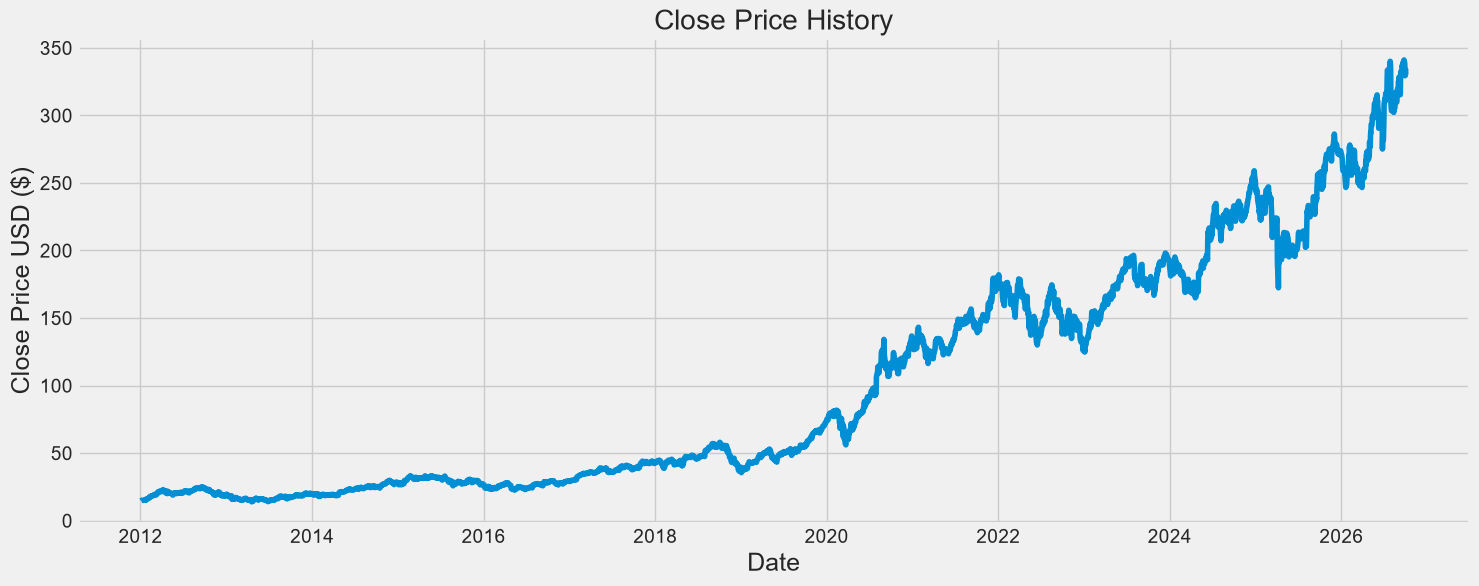

In [21]:
plt.figure(figsize=(16,6))
plt.title('Close Price History')
plt.plot(df['Close'])
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.show()

In [22]:
# Create a new dataframe with only the 'Close column 
data = df.filter(['Close'])
# Convert the dataframe to a numpy array
dataset = data.values
# Get the number of rows to train the model on
training_data_len = int(np.ceil( len(dataset) * .95 ))

training_data_len

3525

In [23]:
# Scale the data
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0,1))
scaled_data = scaler.fit_transform(dataset)

scaled_data

array([[0.00225997],
       [0.00250124],
       [0.00300237],
       ...,
       [0.96713769],
       [0.97743963],
       [0.9749941 ]], shape=(3710, 1))

In [24]:
# Create the training data set 
# Create the scaled training data set
train_data = scaled_data[0:int(training_data_len), :]
# Split the data into x_train and y_train data sets
x_train = []
y_train = []

for i in range(60, len(train_data)):
    x_train.append(train_data[i-60:i, 0])
    y_train.append(train_data[i, 0])
    if i<= 61:
        print(x_train)
        print(y_train)
        print()
        
# Convert the x_train and y_train to numpy arrays 
x_train, y_train = np.array(x_train), np.array(y_train)

# Reshape the data
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))
# x_train.shape

[array([0.00225997, 0.00250124, 0.00300237, 0.00347947, 0.00340632,
       0.00357118, 0.00349585, 0.0033692 , 0.0031967 , 0.00373058,
       0.00421205, 0.00406357, 0.0032502 , 0.00402645, 0.00326221,
       0.00612811, 0.00590648, 0.0061958 , 0.00682138, 0.00720023,
       0.00716857, 0.00705175, 0.0075496 , 0.00801796, 0.00854857,
       0.00940561, 0.01120594, 0.01123323, 0.01223548, 0.01298443,
       0.01169724, 0.0121929 , 0.01218307, 0.0135729 , 0.01337528,
       0.01374103, 0.01439827, 0.01476402, 0.01581758, 0.01658509,
       0.01680672, 0.01688424, 0.01557193, 0.01525531, 0.01530226,
       0.01653597, 0.01688315, 0.01762883, 0.01938658, 0.0217317 ,
       0.02129281, 0.0212939 , 0.02298942, 0.02352003, 0.02314227,
       0.02279727, 0.02243808, 0.02363138, 0.02445021, 0.02479303])]
[np.float64(0.02394581123661242)]

[array([0.00225997, 0.00250124, 0.00300237, 0.00347947, 0.00340632,
       0.00357118, 0.00349585, 0.0033692 , 0.0031967 , 0.00373058,
       0.00421205, 0.00

In [25]:
from keras.models import Sequential
from keras.layers import Input, Dense, LSTM

# Build the LSTM model
model = Sequential()
model.add(Input(shape=(x_train.shape[1], 1)))
model.add(LSTM(128, return_sequences=True))
model.add(LSTM(64, return_sequences=False))
model.add(Dense(25))
model.add(Dense(1))

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
history = model.fit(x_train, y_train, batch_size=32, epochs=5, validation_split=0.1)

Epoch 1/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 9s 58ms/step - loss: 0.0026 - val_loss: 8.7452e-04
Epoch 2/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - loss: 1.4143e-04 - val_loss: 7.4319e-04
Epoch 3/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - loss: 1.5496e-04 - val_loss: 6.1881e-04
Epoch 4/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - loss: 1.1967e-04 - val_loss: 6.1334e-04
Epoch 5/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - loss: 1.1100e-04 - val_loss: 0.0011


In [26]:
# Create the testing data set
# Create a new array containing scaled values from index 1543 to 2002 
test_data = scaled_data[training_data_len - 60: , :]
# Create the data sets x_test and y_test
x_test = []
y_test = dataset[training_data_len:, :]
for i in range(60, len(test_data)):
    x_test.append(test_data[i-60:i, 0])
    
# Convert the data to a numpy array
x_test = np.array(x_test)

# Reshape the data
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1 ))

# Get the models predicted price values 
predictions = model.predict(x_test)
predictions = scaler.inverse_transform(predictions)

# Get the root mean squared error (RMSE)
rmse = np.sqrt(np.mean(((predictions - y_test) ** 2)))
rmse

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step


np.float64(11.290437547354115)

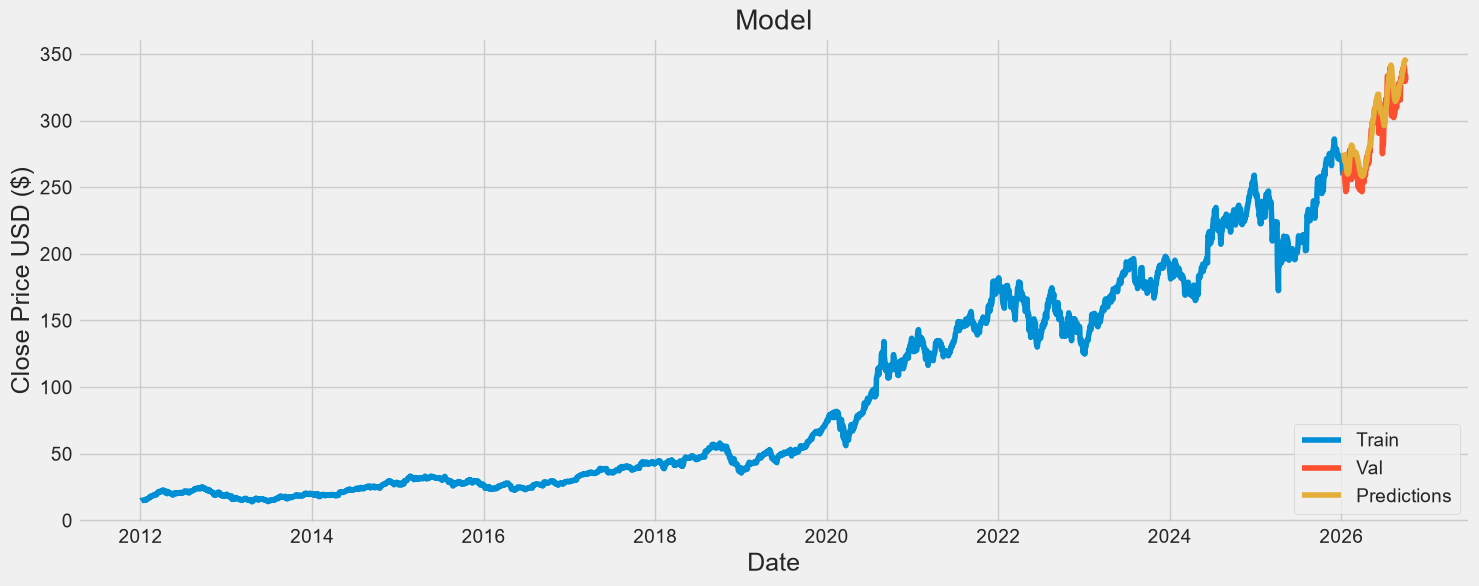

In [27]:
# Plot the data
train = data[:training_data_len]
valid = data[training_data_len:].copy()
valid['Predictions'] = predictions
# Visualize the data
plt.figure(figsize=(16,6))
plt.title('Model')
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.plot(train['Close'])
plt.plot(valid[['Close', 'Predictions']])
plt.legend(['Train', 'Val', 'Predictions'], loc='lower right')
plt.show()

In [28]:
# Show the valid and predicted prices
valid

,Close,Predictions
Date,,
2026-01-09,259.369995,276.000031
2026-01-12,260.250000,274.255188
2026-01-13,261.049988,272.687439
2026-01-14,259.959991,271.401917
2026-01-15,258.209991,270.302460
...,...,...
2026-09-29,329.399994,345.509308
2026-09-30,333.019989,345.376038
2026-10-01,330.320007,345.031738


# 7. Model evaluation
RMSE alone is hard to judge, so the LSTM is compared with a **naive baseline** that simply predicts "tomorrow's close = today's close". Directional accuracy checks whether the model gets the up/down move right.

In [29]:
# Naive baseline: predict yesterday's close for each test day
actual = y_test.ravel()
pred = predictions.ravel()
naive = dataset[training_data_len - 1:-1].ravel()

def report(name, y_true, y_pred):
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mae = np.mean(np.abs(y_true - y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"{name:<12} RMSE: {rmse:8.2f}   MAE: {mae:8.2f}   MAPE: {mape:5.2f}%")

report("LSTM", actual, pred)
report("Naive", actual, naive)

# Directional accuracy: did we predict the sign of the next-day move correctly?
actual_dir = np.sign(actual[1:] - actual[:-1])
pred_dir = np.sign(pred[1:] - actual[:-1])
print(f"\nDirectional accuracy (LSTM): {np.mean(actual_dir == pred_dir) * 100:.1f}%")

LSTM         RMSE:    11.29   MAE:     8.76   MAPE:  3.09%
Naive        RMSE:     4.95   MAE:     3.57   MAPE:  1.23%

Directional accuracy (LSTM): 55.4%


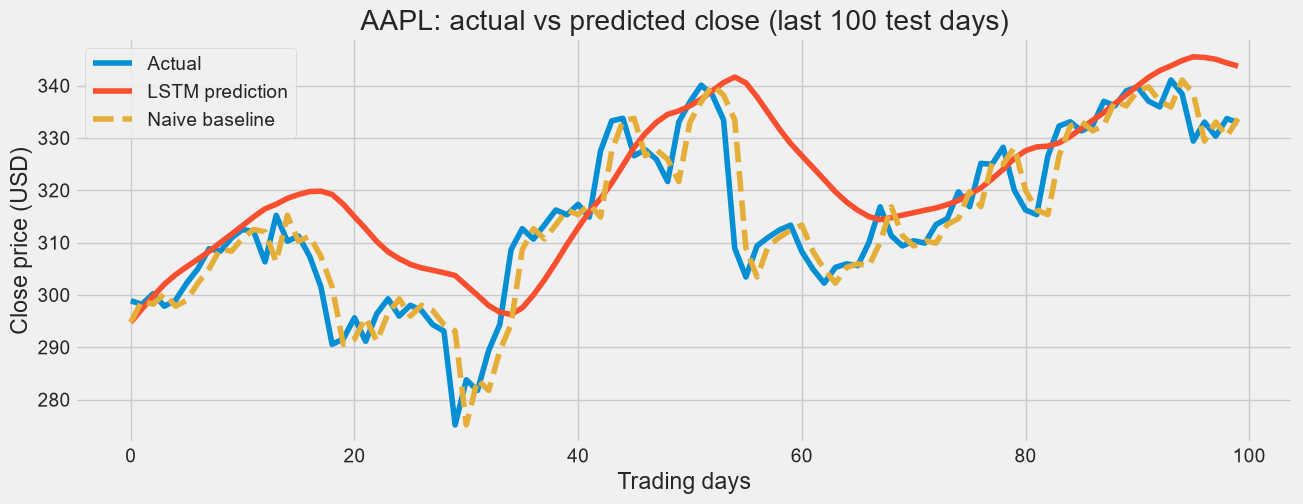

In [30]:
# Zoom in on the last 100 test days
plt.figure(figsize=(14, 5))
plt.plot(actual[-100:], label='Actual')
plt.plot(pred[-100:], label='LSTM prediction')
plt.plot(naive[-100:], label='Naive baseline', linestyle='--')
plt.title(f'{TICKER}: actual vs predicted close (last 100 test days)')
plt.xlabel('Trading days')
plt.ylabel('Close price (USD)')
plt.legend()
plt.show()

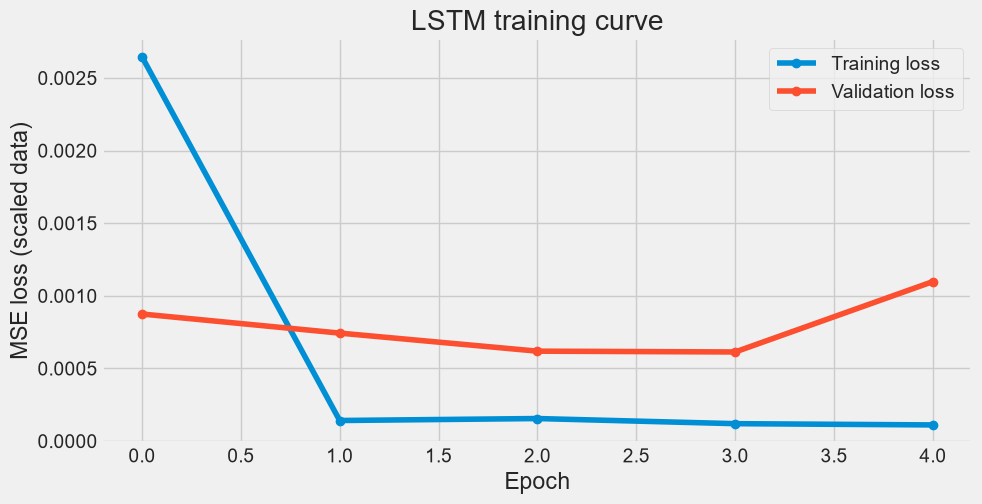

In [31]:
# Training vs validation loss per epoch
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], marker='o', label='Training loss')
plt.plot(history.history['val_loss'], marker='o', label='Validation loss')
plt.title('LSTM training curve')
plt.xlabel('Epoch')
plt.ylabel('MSE loss (scaled data)')
plt.legend()
plt.show()

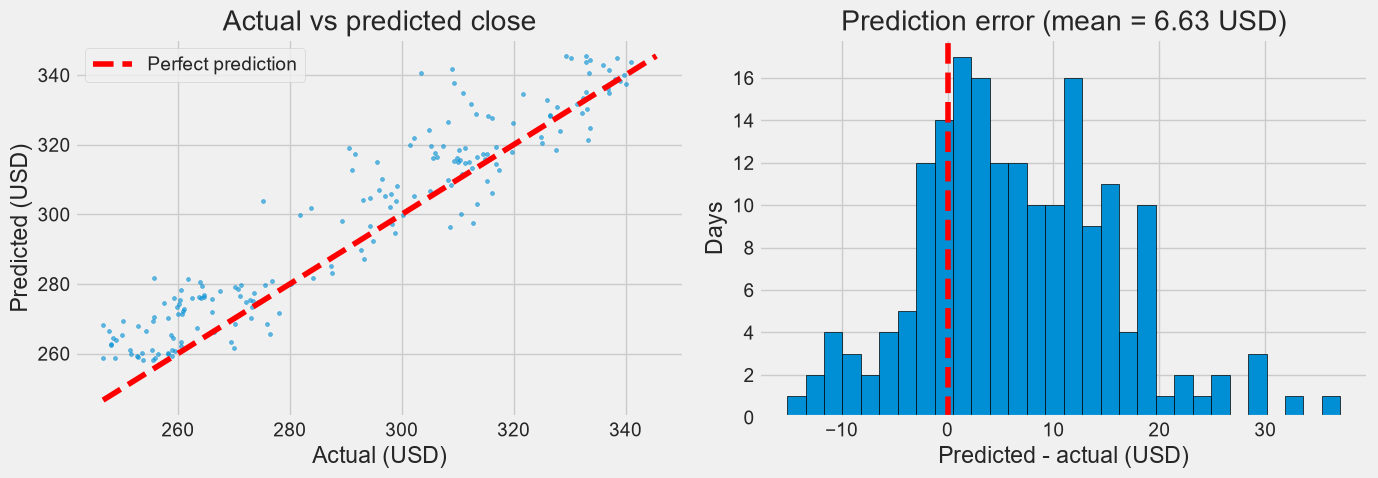

In [32]:
# Actual vs predicted, and distribution of the prediction error
errors = pred - actual

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(actual, pred, s=8, alpha=0.6)
lims = [min(actual.min(), pred.min()), max(actual.max(), pred.max())]
axes[0].plot(lims, lims, color='red', linestyle='--', label='Perfect prediction')
axes[0].set_title('Actual vs predicted close')
axes[0].set_xlabel('Actual (USD)')
axes[0].set_ylabel('Predicted (USD)')
axes[0].legend()

axes[1].hist(errors, bins=30, edgecolor='black')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title(f'Prediction error (mean = {errors.mean():.2f} USD)')
axes[1].set_xlabel('Predicted - actual (USD)')
axes[1].set_ylabel('Days')

plt.tight_layout()
plt.show()

## Limitations and next steps
- In this run the LSTM did **not** beat the naive baseline (RMSE about 14.3 vs 4.95) and its directional accuracy was about 52%, close to a coin flip. Predicting price from past prices alone is hard, and the model was trained for only 5 epochs.
- Only the closing price is used as a feature. Volume, moving averages or other indicators could be added.
- Training longer (with early stopping), tuning the window size and using walk-forward validation instead of a single split would give a fairer evaluation.
- This is a learning project, not a trading signal.

In [33]:
# Save the trained model so it does not need retraining
model.save("lstm_model.keras")

# Summary
- Downloaded and explored market data for four tech stocks with `yfinance`, pandas, Matplotlib and Seaborn.
- Measured trend (moving averages, Bollinger Bands), daily returns, relative performance, rolling volatility, correlation between stocks, and risk vs expected return.
- Built a 2-layer LSTM (128 and 64 units) on 60-day windows of scaled closing prices to predict the next close.
- Evaluated it against a naive "tomorrow = today" baseline and found that the baseline was stronger in this run.